# Model comparison: `new_rules_v2`

Compares **haiku / sonnet / opus** argument maps for four documents under the v2 taxonomy rules (atomic statements):

| doc | source | gold map |
|---|---|---|
| ING | FX Daily (USD, EUR, GBP, CEE) | yes |
| MS | Equity sales and positioning note | yes |
| Ocado | Credit initiation (Overweight) | yes |
| SundayTea | BNPP weekly cross-asset note | no |

This notebook replaces `outputs/new_rules_v2/compare_report.txt`. Every table is recomputed from `outputs/new_rules_v2/{doc}/{model}/`. The comments describe the current outputs; re-read them after any rerun.

In [ ]:
import json
import sys
from collections import Counter
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

from incolor.argumentation.evaluate import evaluate
from incolor.argumentation.ingest import PreprocessConfig, load_document
from incolor.argumentation.pipeline import load_config
from incolor.argumentation.validate import argument_edges
from incolor.argumentation.writer import load_argument_map

RUN_DIR = ROOT / "outputs" / "new_rules_v2"
TEXT_DIR = ROOT / "tests" / "fixtures" / "texts"
GOLD_DIR = ROOT / "tests" / "fixtures" / "gold"
MODELS = ["haiku", "sonnet", "opus"]
DOCS = {
    "ING": "ING.txt",
    "MS": "MS.txt",
    "Ocado": "Ocado.txt",
    "SundayTea": "sunday_tea_bnpp_k_shaped_market.txt",
}
GOLD_FILES = {
    "ING": "ing_fx_daily_argument_map_gold_v06.yaml",
    "MS": "ms_d1_sales_argument_map_gold_v06.yaml",
    "Ocado": "ocado_phase1_argument_map_gold_v06.yaml",
}
CLAIM_TYPES = ["RECOMMENDATION", "VALUATION", "FORECAST", "VIEW", "DATA_POINT", "OBSERVATION"]
MODALITIES = ["ASSERTED", "HEDGED", "SPECULATIVE"]

pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 250)

In [2]:
config = load_config()
preprocess = PreprocessConfig(list(config.furniture_patterns), config.max_input_chars)
sources = {doc: load_document(TEXT_DIR / name, preprocess).text for doc, name in DOCS.items()}

runs = {}
for doc in DOCS:
    for model in MODELS:
        run_dir = RUN_DIR / doc / model
        summary = json.loads((run_dir / "summary.json").read_text(encoding="utf-8"))
        runs[doc, model] = (summary, load_argument_map(run_dir / "argument_map.yaml"))

gold = {doc: load_argument_map(GOLD_DIR / name) for doc, name in GOLD_FILES.items()}

## 1. Structure

Column key: `att` = attempts, `sec` = wall time, `$` = cost, `src chars` = length of the normalised text the model received, `stmts/1k` = statements per 1,000 source characters, `links` = argument-to-argument edges, `isolated` = arguments with no links, `chain` = longest edge chain, `excl` = logged exclusions.

In [3]:
def word_count(text: str) -> int:
    return len(text.split())


def mean(values: list[int]) -> float:
    return sum(values) / len(values) if values else 0.0


rows = []
for (doc, model), (summary, map_) in runs.items():
    chars = len(sources[doc])
    rows.append({
        "doc": doc,
        "model": model,
        "ok": summary["ok"],
        "att": summary["attempts"],
        "sec": round(summary["seconds"]),
        "$": summary["cost_usd"],
        "src chars": chars,
        "args": len(map_.arguments),
        "stmts": len(map_.statements),
        "stmts/1k": len(map_.statements) / chars * 1000,
        "evid": len(map_.evidence),
        "links": summary["edges"],
        "isolated": summary["isolated"],
        "chain": summary["max_chain"],
        "excl": len(map_.exclusions),
        "avg stmt words": mean([word_count(s.statement) for s in map_.statements]),
        "avg evid words": mean([word_count(e.text) for e in map_.evidence]),
    })
structure = pd.DataFrame(rows).set_index(["doc", "model"])
structure.round(2)

ok  att  sec     $  src chars  args  stmts  stmts/1k  evid  links  isolated  chain  excl  avg stmt words  avg evid words
doc       model                                                                                                                             
ING       haiku   True    1  260  0.04       8690    14     60      6.90    43      5         5      2     5           12.07           18.70
          sonnet  True    2   77  0.28       8690     7     36      4.14    33      3         3      4     5           15.61           20.61
          opus    True    1  188  0.63       8690    16     59      6.79    42     12         1      3     4           12.95           19.26
MS        haiku   True    2  172  0.03       3584    11     35      9.77    16      4         6      3     3           14.20           31.62
          sonnet  True    2   61  0.24       3584     6     23      6.42    16      2         3      3     3           18.13           31.25
          opus    True    1  101  0.42       3584     8     27      7.53    15      4         3      4     4           16.44           31.27
Ocado     haiku   True    1  224  0.03       4607     9     45      9.77    19      8         0      4     3           11.58           30.89
          sonnet  True    2   45  0.12       4607     3     17      3.69    14      2         0      2     0           21.53           30.71
          opus    True    2  198  0.68       4607     8     37      8.03    17      7         0      3     4           14.59           32.06
SundayTea haiku   True    2  512  0.08      14517    27    112      7.72    68     10        11      4     7           12.22           29.06
          sonnet  True    1  140  0.28      14517    21     63      4.34    50      7         9      3     5           16.84           31.18
          opus    True    2  494  1.67      14517    34     95      6.54    66     24         6      4     8           14.61           29.27

**Comments**

| aspect | haiku | sonnet | opus |
|---|---|---|---|
| Cost per doc | $0.03–0.08 | $0.12–0.28 | $0.42–1.67 (about 15–20× haiku) |
| Wall time | 172–512 s | **45–140 s** (fastest) | 101–494 s |
| Granularity (stmts/1k) | 6.9–9.8 (finest) | **3.7–6.4 (coarsest)** | 6.5–8.0 |
| Avg statement length | 11.6–14.2 words | 15.6–21.5 words | 12.9–16.4 words |
| Links | 4–10 | 2–7 | **4–24 (most)** |
| Isolated args | 0–11 | 0–9 | 0–6 (fewest) |

- All 12 runs validated within 1–2 attempts, so the v2 rules do not cause repair loops.
- Haiku is the cheapest but not the fastest. It writes the most statements, so it produces more output tokens than sonnet.
- Haiku and opus apply the atomic-statement rule in a similar way. Sonnet merges content into fewer, longer statements. Ocado shows this most clearly: sonnet wrote 17 statements, against 45 for haiku and 37 for opus.
- Opus builds the most connected maps. For example, ING has 12 links and 1 isolated argument with opus, against 5 links and 5 isolated arguments with haiku. Chain depth is 2–4 for every model, so the extra links make maps wider, not deeper.
- Sonnet logged **no exclusions on Ocado**, while haiku and opus each logged 3–4. Sonnet most likely dropped those sentences without recording them.

## 2. Claim types and modality

Counts are per statement. `core types` counts the claim type of each argument's core claim.

In [4]:
rows = []
for (doc, model), (_, map_) in runs.items():
    by_id = {s.id: s for s in map_.statements}
    types = Counter(s.claim_type for s in map_.statements)
    modalities = Counter(s.modality for s in map_.statements)
    rows.append({
        "doc": doc,
        "model": model,
        **{t[:4]: types[t] for t in CLAIM_TYPES},
        **{m: modalities[m] for m in MODALITIES},
        "core types": dict(Counter(by_id[a.core_claim].claim_type[:4] for a in map_.arguments)),
        "exclusion codes": dict(Counter(e.code for e in map_.exclusions)),
    })
claims = pd.DataFrame(rows).set_index(["doc", "model"])
claims

RECO  VALU  FORE  VIEW  DATA  OBSE  ASSERTED  HEDGED  SPECULATIVE                                     core types                                                                  exclusion codes
doc       model                                                                                                                                                                                                    
ING       haiku      0     5    14    24     6    11        46      11            3                         {'VIEW': 7, 'FORE': 7}                               {'TRANSIENT': 3, 'NOT_LOAD_BEARING': 1, 'META': 1}
          sonnet     0     4    12    14     4     2        26       8            2                         {'FORE': 5, 'VIEW': 2}  {'META': 1, 'NOT_LOAD_BEARING': 1, 'VAGUE': 1, 'TANGENTIAL': 1, 'TRANSIENT': 1}
          opus       0     5    20    20     6     8        44      11            4                         {'FORE': 9, 'VIEW': 7}                                                      {'META': 1, 'TRANSIENT': 3}
MS        haiku      3     0     1    15     8     8        32       1            2              {'VIEW': 8, 'RECO': 2, 'FORE': 1}                                                     {'TANGENTIAL': 1, 'META': 2}
          sonnet     2     0     1     9     7     4        21       1            1              {'VIEW': 3, 'RECO': 2, 'FORE': 1}                                                          {'META': 2, 'VAGUE': 1}
          opus       2     0     2     8     8     7        24       1            2              {'VIEW': 5, 'RECO': 2, 'FORE': 1}                                               {'NOT_LOAD_BEARING': 1, 'META': 3}
Ocado     haiku      1     4     9    18     5     8        41       1            3   {'RECO': 1, 'VIEW': 5, 'VALU': 1, 'FORE': 2}                                               {'NOT_LOAD_BEARING': 1, 'META': 2}
          sonnet     1     2     3     8     1     2        16       1            0              {'RECO': 1, 'VALU': 1, 'VIEW': 1}                                                                               {}
          opus       1     3     7    18     4     4        34       1            2   {'RECO': 1, 'VIEW': 5, 'VALU': 1, 'FORE': 1}                                                     {'TANGENTIAL': 2, 'META': 2}
SundayTea haiku      5     1    31    39     8    28        87      18            7             {'FORE': 17, 'VIEW': 6, 'RECO': 4}                               {'NON_CLAIM': 3, 'META': 1, 'NOT_LOAD_BEARING': 3}
          sonnet     6     1    19    23     6     8        51      10            2             {'FORE': 10, 'VIEW': 5, 'RECO': 6}                         {'NOT_LOAD_BEARING': 2, 'TANGENTIAL': 2, 'NON_CLAIM': 1}
          opus       8     2    28    26     9    22        78      12            5  {'VIEW': 7, 'FORE': 18, 'RECO': 8, 'VALU': 1}              {'META': 3, 'NOT_LOAD_BEARING': 2, 'REDUNDANT': 1, 'TANGENTIAL': 2}

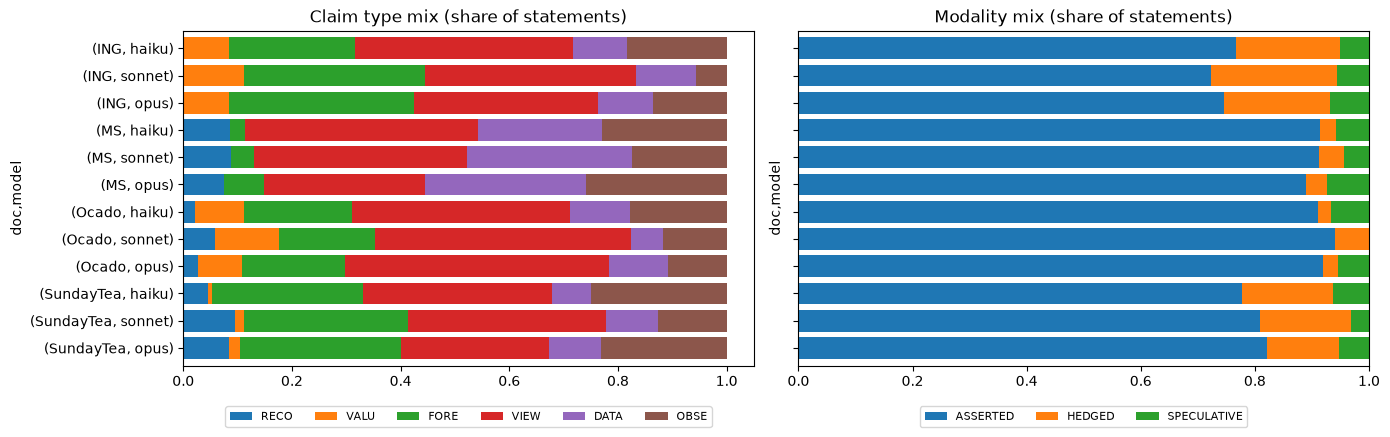

In [5]:
type_cols = [t[:4] for t in CLAIM_TYPES]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
claims[type_cols].div(claims[type_cols].sum(axis=1), axis=0).plot.barh(stacked=True, ax=axes[0], width=0.8)
axes[0].set_title("Claim type mix (share of statements)")
axes[0].invert_yaxis()
axes[0].legend(ncols=6, loc="lower center", bbox_to_anchor=(0.5, -0.2), fontsize=8)
claims[MODALITIES].div(claims[MODALITIES].sum(axis=1), axis=0).plot.barh(stacked=True, ax=axes[1], width=0.8)
axes[1].set_title("Modality mix (share of statements)")
axes[1].invert_yaxis()
axes[1].set_yticklabels([])
axes[1].legend(ncols=3, loc="lower center", bbox_to_anchor=(0.5, -0.2), fontsize=8)
plt.tight_layout()

**Comments**

- **VIEW and FORECAST make up most statements** in every run. RECO appears only in MS, Ocado and SundayTea. ING has no RECO in any model, which is correct because the FX Daily gives forecasts, not trades.
- **Haiku labels more OBSERVATIONs.** It has 11 on ING, against 2 for sonnet and 8 for opus, and 28 on SundayTea, against 8 and 22. Sonnet's longer statements seem to fold observations into VIEWs.
- **Hedging depends on the document, not the model.** HEDGED is about 18–22% of statements on ING and 13–16% on SundayTea, which are strategy notes with a conditional tone. MS and Ocado are almost all ASSERTED (declarative sales and credit notes). The three models agree on this pattern.
- **Opus splits trades into separate arguments.** On SundayTea, opus has 8 RECO cores, against 4 for haiku and 6 for sonnet. For example, it gives short EURAUD (A016), the EURMXN put spread (A017), and each of the three COP trades (A026–A028) their own argument. Haiku bundles these trades together.
- **Exclusion codes are inconsistent.** The models often exclude the same sentence under different codes:
  - "Of course, the key question is where to from here?": NON_CLAIM (haiku), META (opus)
  - "Brazil's first round election will take place today…": NOT_LOAD_BEARING (haiku), TANGENTIAL (opus)
  - "It's hardly a welcoming environment for EUR bulls": excluded as VAGUE by sonnet, but a **core claim** for haiku (A007) and opus (A005)
  
  The rules need clearer boundaries between META and NON_CLAIM and between NOT_LOAD_BEARING and TANGENTIAL.

## 3. Gold scores

> **Caveat:** the gold maps were written before the atomic-statement rules, so their statements are coarser than v2 output. **Precision penalises correct splits.** Treat recall as the main statement metric.

In [6]:
rows = []
for doc, gold_map in gold.items():
    for model in MODELS:
        report = evaluate(runs[doc, model][1], gold_map)
        rows.append({
            "doc": doc,
            "model": model,
            "gold stmts": len(gold_map.statements),
            "gold links": len(argument_edges(gold_map)),
            "evidence recall": report.evidence_recall,
            "stmt P": report.statement_precision,
            "stmt R": report.statement_recall,
            "stmt F1": report.statement_f1,
            "type acc": report.claim_type_accuracy,
            "modality acc": report.modality_accuracy,
            "edge F1": report.edge_f1,
        })
gold_scores = pd.DataFrame(rows).set_index(["doc", "model"])
gold_scores.round(2)

gold stmts  gold links  evidence recall  stmt P  stmt R  stmt F1  type acc  modality acc  edge F1
doc   model                                                                                                    
ING   haiku           40           7             0.95    0.58    0.88     0.70      0.91          0.89     0.17
      sonnet          40           7             0.81    0.78    0.70     0.74      0.82          0.89     0.00
      opus            40           7             0.95    0.63    0.92     0.75      0.86          0.92     0.11
MS    haiku           14           4             1.00    0.37    0.93     0.53      1.00          0.92     0.50
      sonnet          14           4             1.00    0.52    0.86     0.65      0.92          0.83     0.33
      opus            14           4             1.00    0.52    1.00     0.68      0.93          0.93     1.00
Ocado haiku           26           5             1.00    0.53    0.92     0.68      0.96          0.96     0.00
      sonnet          26           5             0.86    0.82    0.54     0.65      0.86          1.00     0.29
      opus            26           5             1.00    0.65    0.92     0.76      0.92          0.96     0.17

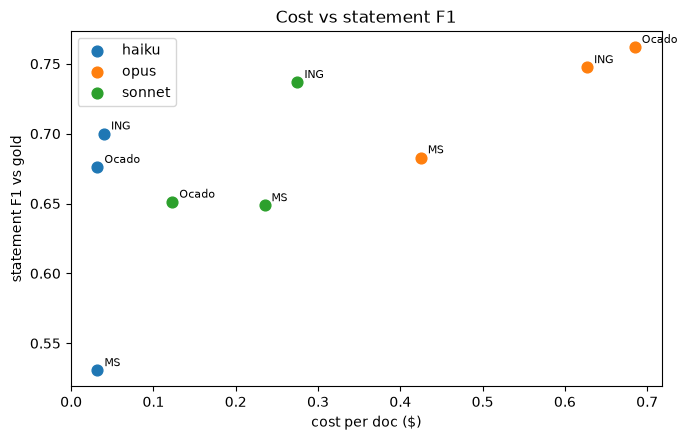

In [7]:
plot_df = gold_scores.join(structure["$"]).reset_index()
fig, ax = plt.subplots(figsize=(7, 4.5))
for model, group in plot_df.groupby("model"):
    ax.scatter(group["$"], group["stmt F1"], label=model, s=60)
    for _, row in group.iterrows():
        ax.annotate(row["doc"], (row["$"], row["stmt F1"]), textcoords="offset points", xytext=(5, 3), fontsize=8)
ax.set_xlabel("cost per doc ($)")
ax.set_ylabel("statement F1 vs gold")
ax.set_title("Cost vs statement F1")
ax.legend()
plt.tight_layout()

**Comments**

| metric | haiku | sonnet | opus |
|---|---|---|---|
| Evidence recall | 0.95–1.00 | **0.81–1.00** | 0.95–1.00 |
| Statement recall | 0.88–0.93 | **0.54–0.86** | **0.92–1.00** |
| Statement F1 | 0.53–0.70 | 0.65–0.74 | **0.68–0.76** (best on all 3) |
| Type / modality acc | 0.91–1.00 / 0.89–0.96 | 0.82–0.92 / 0.83–1.00 | 0.86–0.93 / 0.92–0.96 |
| Edge F1 | 0.00–0.50 | 0.00–0.33 | 0.11–1.00 |

- **Opus has the best statement F1 on every gold document** and recall of at least 0.92.
- **Haiku's recall is close to opus.** Its low precision (0.37–0.58) mostly comes from over-splitting relative to the coarse gold maps, so its statements are not necessarily wrong.
- **Sonnet misses content.** It has the lowest evidence and statement recall, and Ocado recall is only 0.54. This matches its coarse granularity in Section 1.
- **Labelling is not the bottleneck.** Type accuracy is 0.82–1.00 and modality accuracy is 0.83–1.00 for every model.
- **Edge F1 is weak and noisy.** Each gold map has only 4–7 links, so one edge can move F1 by 0.15–0.25. Opus scores 1.00 on MS (4 links) but every model scores 0.17 or lower on ING. Argument linking is the main remaining gap.

## 4. Pairwise agreement between models

Each pair is scored with `evaluate(first, second)`, treating the second model as reference. These scores measure consistency, not correctness.

In [8]:
rows = []
for doc in DOCS:
    for first, second in combinations(MODELS, 2):
        report = evaluate(runs[doc, first][1], runs[doc, second][1])
        rows.append({
            "doc": doc,
            "pair": f"{first}-{second}",
            "stmt overlap F1": report.statement_f1,
            "type agreement": report.claim_type_accuracy,
            "modality agreement": report.modality_accuracy,
            "link F1": report.edge_f1,
        })
pairwise = pd.DataFrame(rows).set_index(["doc", "pair"])
pairwise.round(2)

stmt overlap F1  type agreement  modality agreement  link F1
doc       pair                                                                      
ING       haiku-sonnet             0.69            0.85                0.94     0.00
          haiku-opus               0.89            0.87                0.94     0.12
          sonnet-opus              0.76            0.89                0.94     0.00
MS        haiku-sonnet             0.72            0.86                0.95     0.00
          haiku-opus               0.84            0.85                1.00     0.50
          sonnet-opus              0.84            0.86                0.95     0.33
Ocado     haiku-sonnet             0.55            0.71                0.94     0.00
          haiku-opus               0.90            0.92                1.00     0.53
          sonnet-opus              0.63            0.76                0.94     0.22
SundayTea haiku-sonnet             0.62            0.83                0.87     0.12
          haiku-opus               0.80            0.86                0.93     0.12
          sonnet-opus              0.71            0.82                0.93     0.13

In [9]:
pairwise.groupby("pair", sort=False).mean().round(2)

,stmt overlap F1,type agreement,modality agreement,link F1
pair,,,,
haiku-sonnet,0.64,0.81,0.93,0.03
haiku-opus,0.86,0.87,0.97,0.32
sonnet-opus,0.73,0.83,0.94,0.17


**Comments**

- **Haiku and opus are the closest pair on every document** (MS is a tie with sonnet–opus). Their statement overlap is 0.80–0.90 and type agreement is 0.85–0.92. With the same rules, these two models break text into very similar atomic statements.
- **Sonnet is the outlier.** Its statement overlap with the other models is 0.55–0.84, with a mean of 0.64 against haiku and 0.73 against opus. This mostly reflects its coarser granularity rather than different readings of the text.
- **Modality agreement is at least 0.87 everywhere**, so the HEDGED/SPECULATIVE cues work reliably.
- **Link agreement is poor.** Link F1 is at most 0.53 and usually 0.13 or lower. The models mostly agree on *which* statements exist but not on *how arguments connect*. The gold edge F1 in Section 3 shows the same weakness, so linking is the least stable part of the pipeline.

## 5. Maps

How to read the maps:

- `A001 [TYPE/M] brief`: argument ID, core claim type (first 4 letters) and modality (`A`sserted / `H`edged / `S`peculative).
- Member prefixes: `supp`orting, `rati`onale, `risk`s, `cond`itions, `cata`lysts, `qual`ifiers.
- `<== Axxx`: the member is also the core claim of another argument, which counts as a **link**.
- `EXCL CODE`: a source sentence the model excluded, cut to 100 characters.

Set `MAP_DOCS` to limit the output.

In [10]:
ROLES = ["supporting", "rationale", "risks", "conditions", "catalysts", "qualifiers"]
MAP_DOCS = list(DOCS)


def render_map(map_) -> str:
    by_id = {s.id: s for s in map_.statements}
    owner = {}
    for argument in map_.arguments:
        owner.setdefault(argument.core_claim, argument.id)
    lines = []
    for argument in map_.arguments:
        core = by_id[argument.core_claim]
        lines.append(f"{argument.id} [{core.claim_type[:4]}/{core.modality[0]}] {core.brief}")
        for role in ROLES:
            for statement_id in getattr(argument, role):
                s = by_id[statement_id]
                link = owner.get(statement_id)
                suffix = f" <== {link}" if link and link != argument.id else ""
                lines.append(f"   {role[:4]} {s.claim_type[:4]}/{s.modality[0]}: {s.brief}{suffix}")
    lines.extend(f"   EXCL {e.code}: {e.text[:100]}" for e in map_.exclusions)
    return "\n".join(lines)


for doc in MAP_DOCS:
    for model in MODELS:
        print(f"\n===== {doc} / {model} =====")
        print(render_map(runs[doc, model][1]))


===== ING / haiku =====
A001 [VIEW/A] Little reason to call imminent dollar reversal
   supp VIEW/A: Reversal needs a clear catalyst; none seen
   supp VIEW/A: Fed tightening expectations stickier than most central banks
   supp VIEW/A: Fed expectations limit USD downside if oil retreats
   supp VIEW/A: Bond weakness sustains defensive currency demand
   supp VIEW/A: Consensus limits scope for negative USD reaction
   supp VIEW/A: Firmer oil keeps dollar on solid footing
   rati OBSE/A: March 2025 Sell-America shock derailed overbought USD
   rati OBSE/A: March 2026 static Fed blocked geopolitical USD gains
   rati DATA/A: Consensus expects 0.2% core CPI MoM
   risk VIEW/H: Technical indicators point to stretched USD rally <== A002
   risk VIEW/H: US midterms an underappreciated USD risk <== A003
A002 [VIEW/H] Technical indicators point to stretched USD rally
   supp VALU/A: USD overvalued vs G10 except GBP on model
   supp VALU/A: USD 1.1% overvalued vs G10, equal-weighted
   supp VA

**Comments**

- **ING:** opus splits the EUR thesis into a small chain. "EUR/USD cut to 1.13" (A003) is supported by A004 (fiscal premium) and A005 (EUR bulls), with risk A006 and condition A007. Sonnet puts the same content into a single A003 with 7 members. Haiku treats "Little reason to call imminent dollar reversal" as a VIEW, while sonnet and opus treat it as a FORECAST, which is a common VIEW/FORE boundary case.
- **MS:** all three models find the same backbone: sentiment, then asymmetry, then the "use hedges" recommendation. Haiku adds separate arguments for European selling and retail drop-off, which sonnet and opus fold into existing arguments.
- **Ocado:** haiku and opus produce nearly the same structure: an Overweight core with platform, carry, valuation and balance-sheet sub-arguments, plus 4 explicit risks. Sonnet merges the four risks into one vague "Key risks to recommendation" statement.
- **SundayTea:** opus links shared drivers across sections. "BanRep has turned hawkish" (A025) feeds three COP trades, and "No clear path to lower energy prices" (A029) feeds the CNB, NBH and NBP calls. Haiku and sonnet repeat the energy driver as a separate statement in each argument, and sonnet does the same with "Banrep hawkish". This accounts for most of opus's higher link count.

## 6. Takeaways

| | haiku | sonnet | opus |
|---|---|---|---|
| Statement extraction | strong recall, over-splits | coarse, misses content | strongest |
| Argument linking | moderate, many isolated | sparse | richest, reuses shared drivers |
| Cost | lowest | mid | highest |
| Suggested use | bulk / first-pass extraction | not preferred under v2 rules | final maps |

**Next steps**

1. **Re-adjudicate the gold maps** under the atomic-statement rules so that precision becomes meaningful.
2. **Make the edge evaluation more robust.** Add more gold links, or add a role-agnostic edge F1 alongside the strict one.
3. **Clarify the exclusion code definitions** (META vs NON_CLAIM, NOT_LOAD_BEARING vs TANGENTIAL), and require an exclusion record for every dropped sentence.